# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [1]:
# N Soma Sekhar
# Roll No: 1024170194

ROLL_NO = 1024170194
NAME = "N Soma Sekhar"

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"


### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170194   Name: N Soma Sekhar   Fingerprint: 75296DC5   Tickets: 16

Ticket_ID                                                                            Ticket_Text
      T01 Python is showing an error after resetting my password. The same problem occurs again.
      T02                                                          Version 2.0.1 crashes at 99%.
      T03                      I couldn't connect to the MATLAB since yesterday. This is urgent.
      T04                                                     Dr. Rao's lab PC (No. 14) is down.
      T05                          The VPN was working yesterday. The same problem occurs again.
      T06             LMS keeps asking for login since yesterday. The same problem occurs again.
      T07     Server keeps asking for login while uploading the file. Is there another solution?
      T08                                                  It's not the laptop; it's the server.
      T09                                 

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [5]:
rows = []
for i in range(len(df)):
    tid = df['Ticket_ID'][i]
    p = process_ticket(df['Ticket_Text'][i])
    rows.append([tid, len(p['sentences']), len(p['tokens']), len(p['punct']), len(p['stops']),
                 len(set(p['tokens'])), len(p['final'])])

table = pd.DataFrame(rows, columns=['Ticket', 'Sentences', 'Tokens', 'Punctuation', 'Stopwords', 'Unique', 'Final'])
total = ['TOTAL', table['Sentences'].sum(), table['Tokens'].sum(), table['Punctuation'].sum(),
         table['Stopwords'].sum(), table['Unique'].sum(), table['Final'].sum()]
table.loc[len(table)] = total
table

,Ticket,Sentences,Tokens,Punctuation,Stopwords,Unique,Final
0,T01,2,16,2,7,15,7
1,T02,1,7,2,1,7,4
2,T03,2,14,2,5,13,7
3,T04,2,13,4,3,12,6
4,T05,2,12,2,5,10,5
5,T06,2,14,2,4,13,8
6,T07,2,15,2,5,15,8
7,T08,1,11,2,5,8,4
8,T09,2,11,2,6,11,3
9,T10,2,11,2,3,11,6


In [6]:
for tid in FOCUS:
    text = df[df['Ticket_ID'] == tid]['Ticket_Text'].values[0]
    p = process_ticket(text)
    print(tid, ":", text)
    print("tokens:", p['tokens'])
    print("punctuation:", p['punct'])
    print("stopwords:", p['stops'])
    print("final:", p['final'])
    print()

T12 : I was locked out of the student portal since yesterday. This is urgent.
tokens: ['i', 'was', 'locked', 'out', 'of', 'the', 'student', 'portal', 'since', 'yesterday', '.', 'this', 'is', 'urgent', '.']
punctuation: ['.', '.']
stopwords: ['i', 'was', 'out', 'of', 'the', 'this', 'is']
final: ['locked', 'student', 'portal', 'since', 'yesterday', 'urgent']

T14 : MATLAB stopped responding when I use mobile hotspot. This is urgent.
tokens: ['matlab', 'stopped', 'responding', 'when', 'i', 'use', 'mobile', 'hotspot', '.', 'this', 'is', 'urgent', '.']
punctuation: ['.', '.']
stopwords: ['when', 'i', 'this', 'is']
final: ['matlab', 'stopped', 'responding', 'use', 'mobile', 'hotspot', 'urgent']



In [7]:
weird = []
for t in df['Ticket_Text']:
    for w in process_ticket(t)['final']:
        if not w.isalpha() and w not in weird:
            weird.append(w)
print(weird)

['2.0.1', '99', "n't", 'dr.', "'s", '14', '1023-03-021']


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* The final tokens that are not real words are **n't**, **'s** and **dr.**, plus the numbers **2.0.1, 99, 14 and 1023-03-021**.
- **n't** comes from "couldn't" in T03. word_tokenize splits it into "could" + "n't", and "n't" is not in the NLTK stopword list, so it stays.
- **'s** comes from "Rao's" in T04 and "It's" / "it's" in T08. The tokenizer splits off the 's, and it is also not a stopword.
- **dr.** comes from "Dr.". The tokenizer keeps the dot with the abbreviation, and is_punct() is False because the token has letters in it.
- The numbers and the roll number are kept because they are not punctuation or stopwords.

There is no "ca" in my data because none of my tickets has "can't".

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [8]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

import re

all_text = " ".join(df['Ticket_Text'])

long_words = r"\b[A-Za-z]{6,}\b"
numbers = r"\d+(?:[.,]\d+)*"
caps = r"\b[A-Z][A-Za-z]*\b"
vowel = r"\b[AEIOUaeiou][A-Za-z]*\b"

print("Words longer than 5 letters:", re.findall(long_words, all_text))
print()
print("Numbers:", re.findall(numbers, all_text))
print()
print("Capitalized words:", re.findall(caps, all_text))
print()
print("Words starting with vowel:", re.findall(vowel, all_text))

Words longer than 5 letters: ['Python', 'showing', 'resetting', 'password', 'problem', 'occurs', 'Version', 'crashes', 'couldn', 'connect', 'MATLAB', 'yesterday', 'urgent', 'working', 'yesterday', 'problem', 'occurs', 'asking', 'yesterday', 'problem', 'occurs', 'Server', 'asking', 'uploading', 'another', 'solution', 'laptop', 'server', 'working', 'Password', 'stopped', 'responding', 'yesterday', 'locked', 'student', 'portal', 'yesterday', 'urgent', 'cannot', 'access', 'projector', 'uploading', 'worked', 'yesterday', 'MATLAB', 'stopped', 'responding', 'mobile', 'hotspot', 'urgent', 'Matlab', 'crashes', 'opening', 'uploading', 'another', 'computer', 'getting', 'logged', 'laptop', 'laptop']

Numbers: ['2.0.1', '99', '14', '1023', '03', '021']

Capitalized words: ['Python', 'The', 'Version', 'I', 'MATLAB', 'This', 'Dr', 'Rao', 'PC', 'No', 'The', 'VPN', 'The', 'LMS', 'The', 'Server', 'Is', 'It', 'The', 'VPN', 'Can', 'Password', 'Can', 'My', 'I', 'This', 'I', 'It', 'MATLAB', 'I', 'This', 'Ma

In [9]:
email = r"[\w.+-]+@[\w-]+(?:\.[\w-]+)+"
url = r"(?:https?://|www\.)\S+?(?=[.,;]?(?:\s|$))"
phone = r"(?:\+91[\s-]?)?\d{5}[\s-]?\d{5}|\b0\d{3}-\d{3}-\d{4}\b"

def clean_text(t):
    t = re.sub(email, "<EMAIL>", t)
    t = re.sub(url, "<URL>", t)
    t = re.sub(phone, "<PHONE>", t)
    return t

for line in TEST_LINES:
    print(line)
    print("->", clean_text(line))
    print()

for t in df['Ticket_Text']:
    if clean_text(t) != t:
        print(t, "->", clean_text(t))

Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
-> Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>.

Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
-> Call <PHONE>, <PHONE> or <PHONE>. Version 2.0.1 is 95.5% done; fee Rs 1,250.

The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
-> The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.



In [10]:
for line in TEST_LINES:
    print(re.findall(numbers, line))

[]
['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.5', '1,250']
['5.30']


In [11]:
always_caps = ["I", "Python", "Matlab", "Dr"]
start_words = []
for t in df['Ticket_Text']:
    for sen in sent_tokenize(t):
        first = re.findall(caps, sen)
        if len(first) > 0 and sen.startswith(first[0]):
            w = first[0]
            if w not in always_caps and not w.isupper():
                start_words.append(w)

print("total capitalized words:", len(re.findall(caps, all_text)))
print("capitalized only because they start a sentence:", len(start_words))
print(start_words)

total capitalized words: 35
capitalized only because they start a sentence: 19
['The', 'Version', 'This', 'The', 'The', 'The', 'Server', 'Is', 'It', 'The', 'Can', 'Password', 'Can', 'My', 'This', 'It', 'This', 'It', 'Can']


**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:* My tickets have **35** capitalized words. **19** of them are capitalized only because they start a sentence: The (5), This (3), It (3), Can (3), Version, Server, Is, Password and My. The other 16 are always capitalized: I (5), MATLAB / Matlab (3), VPN (2), Python, LMS, PC, Dr, Rao and No.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [12]:
from nltk.tokenize import RegexpTokenizer

pattern = (r"(?:https?://|www\.)\S+?(?=[.,;]?(?:\s|$))"
           r"|[\w.+-]+@[\w-]+(?:\.[\w-]+)+"
           r"|(?:\+91[\s-]?)?\d{5}[\s-]?\d{5}"
           r"|\d{4}-\d{3}-\d{4}"
           r"|\d+(?:[.,]\d+)+"
           r"|\w+(?:[-']\w+)*"
           r"|[^\w\s]")
tokenizer = RegexpTokenizer(pattern)

def my_tokenize(text):
    return tokenizer.tokenize(text)

for line in TEST_LINES:
    print(my_tokenize(line))
    print(word_tokenize(line))
    print()

['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

['The', 'state-of-the-art', 'lab', "isn't", 'open', ';', 'log-in', 'at', '5.30', 'p', '.', 'm', '.', "didn't", 'work', '.']
['The', 'state-of-the-art', 'lab', 'is', "n't", 'open', ';', 'log-in', 'at', '5.30', 'p.m.', 'did', "n't", 'work', '.']



In [13]:
diff = 0
for i in range(len(df)):
    t = df['Ticket_Text'][i]
    a = my_tokenize(t)
    b = word_tokenize(t)
    if a != b:
        diff = diff + 1
        print(df['Ticket_ID'][i], t)
        print("   my_tokenize  :", a)
        print("   word_tokenize:", b)
print()
print("tickets tokenized differently:", diff, "out of", len(df))

T03 I couldn't connect to the MATLAB since yesterday. This is urgent.
   my_tokenize  : ['I', "couldn't", 'connect', 'to', 'the', 'MATLAB', 'since', 'yesterday', '.', 'This', 'is', 'urgent', '.']
   word_tokenize: ['I', 'could', "n't", 'connect', 'to', 'the', 'MATLAB', 'since', 'yesterday', '.', 'This', 'is', 'urgent', '.']
T04 Dr. Rao's lab PC (No. 14) is down.
   my_tokenize  : ['Dr', '.', "Rao's", 'lab', 'PC', '(', 'No', '.', '14', ')', 'is', 'down', '.']
   word_tokenize: ['Dr.', 'Rao', "'s", 'lab', 'PC', '(', 'No', '.', '14', ')', 'is', 'down', '.']
T08 It's not the laptop; it's the server.
   my_tokenize  : ["It's", 'not', 'the', 'laptop', ';', "it's", 'the', 'server', '.']
   word_tokenize: ['It', "'s", 'not', 'the', 'laptop', ';', 'it', "'s", 'the', 'server', '.']
T13 I cannot access the projector while uploading the file. It worked yesterday.
   my_tokenize  : ['I', 'cannot', 'access', 'the', 'projector', 'while', 'uploading', 'the', 'file', '.', 'It', 'worked', 'yesterday', '

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:* **4 out of 16** tickets are tokenized differently:
- T03: my_tokenize keeps "couldn't", but word_tokenize gives "could" + "n't"
- T04: word_tokenize keeps "Dr." together but splits "Rao's"; my_tokenize does the opposite
- T08: "It's" and "it's" are split by word_tokenize
- T13: word_tokenize splits "cannot" into "can" + "not"

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [14]:
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk.corpus import wordnet

words = []
for t in df['Ticket_Text']:
    for w in process_ticket(t)['final']:
        if w not in words:
            words.append(w)
words.sort()
print(len(words), "unique final tokens")
print(words)

56 unique final tokens
["'s", '1023-03-021', '14', '2.0.1', '99', 'access', 'another', 'asking', 'check', 'computer', 'connect', 'could', 'crashes', 'dr.', 'error', 'file', 'getting', 'hotspot', 'keep', 'keeps', 'lab', 'laptop', 'lms', 'locked', 'logged', 'login', 'matlab', 'mobile', "n't", 'occurs', 'opening', 'password', 'pc', 'portal', 'problem', 'projector', 'python', 'rao', 'resetting', 'responding', 'roll', 'server', 'showing', 'since', 'solution', 'stopped', 'student', 'uploading', 'urgent', 'use', 'version', 'vpn', 'worked', 'working', 'works', 'yesterday']


*Your answer:* For the RegexpStemmer I chose the suffix **ing$** with min=6. I looked at my unique final tokens, and the most common ending is -ing: 8 words (showing, resetting, working, asking, uploading, responding, opening, getting). min=6 means short words won't be cut.

In [15]:
ps = PorterStemmer()
ls = LancasterStemmer()
rs = RegexpStemmer("ing$", min=6)
lem = WordNetLemmatizer()

def get_pos(tag):
    if tag.startswith('J'):
        return wordnet.ADJ
    elif tag.startswith('V'):
        return wordnet.VERB
    elif tag.startswith('R'):
        return wordnet.ADV
    else:
        return wordnet.NOUN

rows = []
for w, tag in nltk.pos_tag(words):
    p = ps.stem(w)
    l = ls.stem(w)
    r = rs.stem(w)
    wn = lem.lemmatize(w, get_pos(tag))
    if not (p == l == r == wn):
        rows.append([w, tag, p, l, r, wn])

stem_table = pd.DataFrame(rows, columns=['word', 'POS', 'Porter', 'Lancaster', 'Regexp', 'WordNet'])
print(len(stem_table), "words where the outputs differ")
stem_table

27 words where the outputs differ


,word,POS,Porter,Lancaster,Regexp,WordNet
0,another,DT,anoth,anoth,another,another
1,computer,NN,comput,comput,computer,computer
2,crashes,VB,crash,crash,crashes,crash
3,error,NN,error,er,error,error
4,file,NN,file,fil,file,file
5,getting,VBG,get,get,gett,get
6,keeps,NNS,keep,keep,keeps,keep
7,lms,NN,lm,lms,lms,lm
8,locked,VBD,lock,lock,locked,lock
9,logged,JJ,log,log,logged,logged


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:* **Over-stemming:** Lancaster changes "projector" to "project", so it would be treated the same as the word "project", which means something different. Lancaster also cuts "student" to "stud" and "error" to "er".

**Under-stemming:** the Regexp stemmer gives "getting" → "gett" and "resetting" → "resett", so they don't match "get" and "reset". It also leaves "works" and "worked" as different words, even though they have the same root "work".

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

In [16]:
S1 = []
S2 = []
S3 = []
for t in df['Ticket_Text']:
    p = process_ticket(t)
    S1 = S1 + p['tokens']
    for w in p['tokens']:
        if not is_punct(w):
            S2.append(w)
    S3 = S3 + p['final']
S4 = [ps.stem(w) for w in S3]

stats = []
for name, s in [('S1', S1), ('S2', S2), ('S3', S3), ('S4', S4)]:
    stats.append([name, len(s), len(set(s)), round(len(set(s)) / len(s), 3)])
pd.DataFrame(stats, columns=['Set', 'Tokens', 'Unique', 'TTR'])

,Set,Tokens,Unique,TTR
0,S1,206,87,0.422
1,S2,172,81,0.471
2,S3,93,56,0.602
3,S4,93,53,0.570


In [17]:
from collections import Counter

print("Top 10 of S1:", Counter(S1).most_common(10))
print()
print("Top 10 of S3:", Counter(S3).most_common(10))

Top 10 of S1: [('.', 26), ('the', 14), ('is', 8), ('yesterday', 6), ('this', 6), ('i', 5), ('since', 4), ('while', 4), ('?', 4), ('it', 4)]

Top 10 of S3: [('yesterday', 6), ('since', 4), ('problem', 3), ('occurs', 3), ('matlab', 3), ('urgent', 3), ("'s", 3), ('uploading', 3), ('file', 3), ('laptop', 3)]


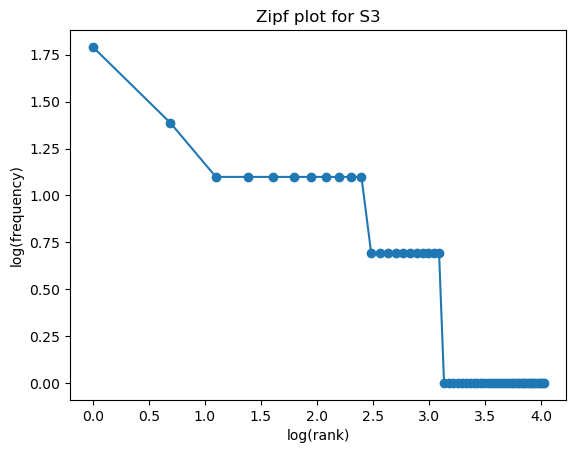

In [18]:
import numpy as np
import matplotlib.pyplot as plt

freq = sorted(Counter(S3).values(), reverse=True)
rank = range(1, len(freq) + 1)
plt.plot(np.log(rank), np.log(freq), 'o-')
plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.title("Zipf plot for S3")
plt.show()

In [19]:
b1 = []
b3 = []
for t in df['Ticket_Text']:
    p = process_ticket(t)
    b1 = b1 + list(nltk.bigrams(p['tokens']))
    b3 = b3 + list(nltk.bigrams(p['final']))

print("Top 5 bigrams of S1:", Counter(b1).most_common(5))
print()
print("Top 5 bigrams of S3:", Counter(b3).most_common(5))

Top 5 bigrams of S1: [(('yesterday', '.'), 6), (('since', 'yesterday'), 4), (('.', 'the'), 3), (('the', 'same'), 3), (('same', 'problem'), 3)]

Top 5 bigrams of S3: [(('since', 'yesterday'), 4), (('problem', 'occurs'), 3), (('uploading', 'file'), 3), (('yesterday', 'urgent'), 2), (('vpn', 'working'), 2)]


**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:* - **S1 → S2** (0.422 → 0.471): the 34 punctuation tokens are removed. They repeat a lot ("." alone appears 26 times) but only 6 of them are unique, so TTR goes up.
- **S2 → S3** (0.471 → 0.602): the 79 stopwords are removed. They are very repetitive ("the" 14 times, "is" 8 times), so TTR goes up again.
- **S3 → S4** (0.602 → 0.570): Porter stemming merges different forms of the same word, like works / worked / working → work and keep / keeps → keep. The number of tokens stays 93, but the unique tokens drop from 56 to 53, so TTR goes down.

---
## Q6. Interpretation

**(a)** TTR goes up from S1 to S3 because punctuation and stopwords repeat a lot, so removing them takes out many tokens but only a few unique ones (0.422 → 0.471 → 0.602). It goes down in S4 because stemming joins forms like works / worked / working into "work", so there are fewer unique tokens (56 → 53) but the same total (0.570).

**(b)** In T03, word_tokenize splits "couldn't" into ["could", "n't"] because it follows the Penn Treebank rules, which separate contractions. My pattern `\w+(?:[-']\w+)*` allows an apostrophe inside a word, so it keeps ["couldn't"] as one token.

**(c)** Lancaster stems "student" → "stud" and "error" → "er". These are not real words, and "stud" even has a different meaning, so the meaning is lost.

**(d)** "opening" (VBG): the WordNet lemmatizer with the verb POS gives "open", which is the correct base word, but Lancaster gives "op". Also, "computer" stays "computer" with the lemmatizer, while Porter and Lancaster change it to "comput".